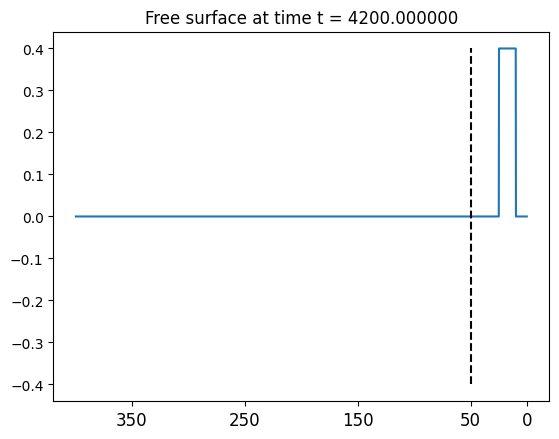

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

phi = lambda x: 1 if -10000 > x and x > -25000 else 0
x_max = -400000 # max x-value in meters
dx = 200 # mesh width in meters
g = 9.81 # gravitational acceleration
t_f = 4200 # end time
number_of_cells = abs(int(x_max/dx))
domain = np.linspace(start=0, stop=x_max, num=number_of_cells)

b_x = lambda x: -4000 if -50000 >= x else -200 # bathymetry defining function
b = np.array([b_x(x) for x in domain]) # bathymetry array
h = np.array([phi(x) * 0.4 - b_x(x) for x in domain]) # water height array
hu = np.zeros(number_of_cells) # water momentum array

# update arrays
h_left_up = np.zeros(number_of_cells)
h_right_up = np.zeros(number_of_cells)
hu_left_up = np.zeros(number_of_cells)
hu_right_up = np.zeros(number_of_cells)

def plot_graph(domain, h, b, t=-1):
    plt.plot(domain, h+b)
    plt.plot([-50000,-50000], [-0.4,0.4], 'k--')
    plt.xticks([-350000,-250000,-150000, -50000, 0],['350','250','150','50','0'],fontsize=12)
    plt.title("Free surface at time t = %f" % t)
    #plt.savefig("./adjoint_%f.svg" % t)
    plt.show()

plot_graph(domain[1:-2], h[1:-2], b[1:-2], 4200)

In [2]:
# solver
from adjoint_solver import compute_net_updates

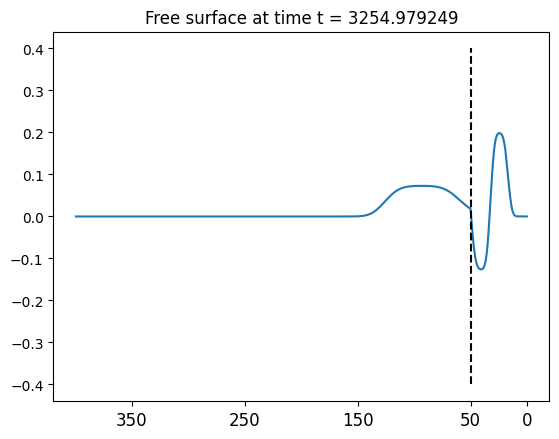

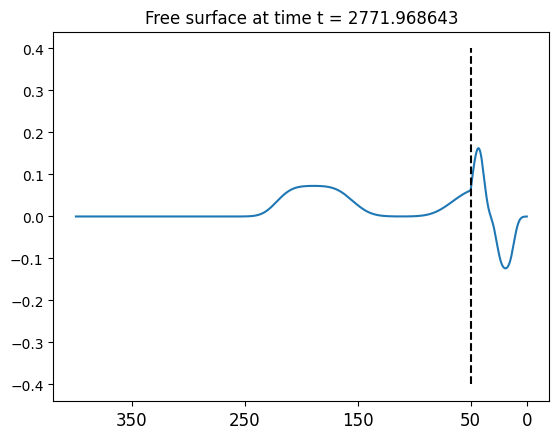

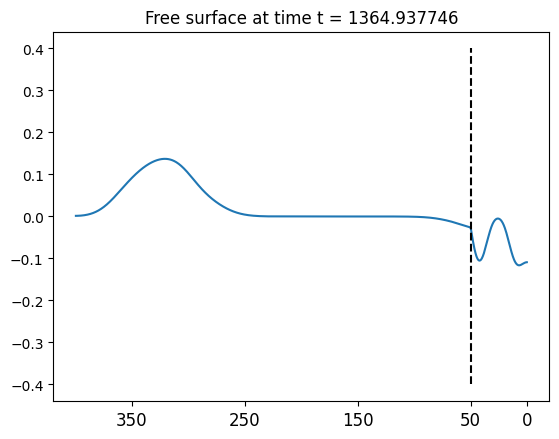

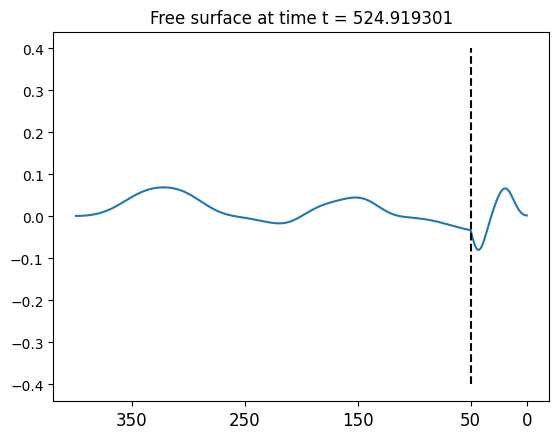

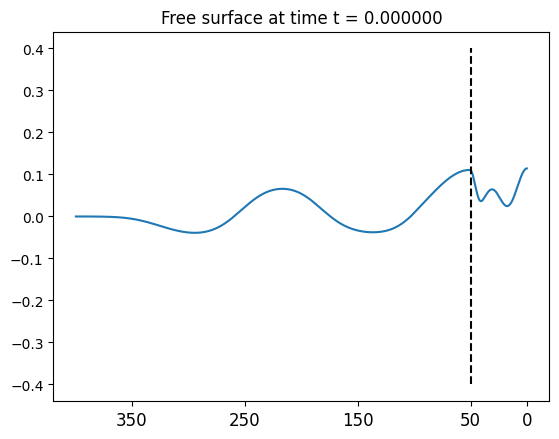

In [3]:
t = 0
# Visualization variables:
eta_values = []
t_values = []
t_count = 0

while t < t_f:
    if t_count == 0 and t >= 4200 - 3255:
        plot_graph(domain[1:-2], h[1:-2], b[1:-2], t_f - t)
        t_count = t_count + 1
    elif t_count == 1 and t>= 4200 - 2772:
        plot_graph(domain[1:-2], h[1:-2], b[1:-2], t_f - t)
        t_count = t_count + 1
    elif t_count == 2 and t >= 4200 - 1365:
        plot_graph(domain[1:-2], h[1:-2], b[1:-2], t_f - t)
        t_count = t_count + 1
    elif t_count == 3 and t >= 4200 - 525:
        plot_graph(domain[1:-2], h[1:-2], b[1:-2], t_f - t)
        t_count = t_count + 1
    h[0] = h[1]
    hu[0] = 0.0
    h[-1] = h[-2]
    hu[-1] = 0.0
    
    eta_values.append([abs(eta) for eta in h[1:-2]+b[1:-2]])
    t_values.append(t)
    max_wave_speed = 0
    # calculate fluxes
    for i in range(1, len(h)):
        h_left_up[i-1], hu_left_up[i-1], h_right_up[i-1], hu_right_up[i-1], edge_speed = compute_net_updates(h[i-1], h[i], hu[i-1], hu[i], b[i-1], b[i])
        max_wave_speed = max(max_wave_speed, edge_speed)
    
    max_time_step = dx / max_wave_speed * 0.4

    # wave propagation
    # https://www.clawpack.org/wp_algorithms.html?highlight=godunov%20splitting
    for i in range(1, len(h)):
        h[i] -= max_time_step / dx * (h_right_up[i-1] + h_left_up[i])
        hu[i] -= max_time_step / dx * (hu_right_up[i-1] + hu_left_up[i])

    h[0] = h[1]
    hu[0] = 0.0
    h[-1] = h[-2]
    hu[-1] = 0.0
   
    t = t + max_time_step

t_values.append(t)
eta_values.append([abs(eta) for eta in h[1:-2]+b[1:-2]])
plot_graph(domain[1:-2], h[1:-2], b[1:-2], 0)

In [4]:
from pylab import * 
tmax = t_values[-1]
Xa = domain[1:-2]
Ta = t_values
eta_values.reverse()
etaanorm = eta_values
textsize = 12
size = 12
t_2 = 3800

In [5]:
etashift = []
for start_index in range(0,len(t_values)):
    i_t = t_values[start_index]
    etamax = etaanorm[start_index]
    
    for temp_index in range(start_index+1, len(t_values)):
        if t_values[temp_index - 1] <= i_t + (tmax - t_2) and t_values[temp_index] > i_t:
            etamax = np.maximum(etamax, etaanorm[temp_index])
        else:
            break
            
    etashift.append(etamax)

In [ ]:
figure(1,(10,8))
clf()

axes([0.08,0.09,0.42,0.83])
contourf(Xa,Ta,etaanorm,[0.01,1.0],colors=['b'],alpha=0.3)
plot([-50000,-50000],[0,tmax],'k--')
title("Adjoint Solution Contours Single Point", fontsize=textsize)
yticks([3600, 1800, 0],['1.0','0.5','0.0'],fontsize=size)
xticks([-350000,-250000,-150000, -50000, 0],['350','250','150','50','0'],fontsize=size)
xlabel("Kilometers offshore",fontsize=textsize)
ylabel("Hours",fontsize=textsize)
axes([0.56,0.09,0.42,0.83])
contourf(Xa,Ta,etashift,[0.01,1.0],colors=['b'],alpha=0.3)
plot([-50000,-50000],[0,tmax],'k--')
title("Adjoint Solution Contours Time Range", fontsize=textsize)
xticks([-350000,-250000,-150000, -50000, 0],['350','250','150','50','0'],fontsize=size)
tick_params(axis='y', labelleft='off')
xlabel("Kilometers offshore",fontsize=textsize)
yticks([3600, 1800, 0],['1.0','0.5','0.0'],fontsize=size)
savefig("adjoint_contours.svg")

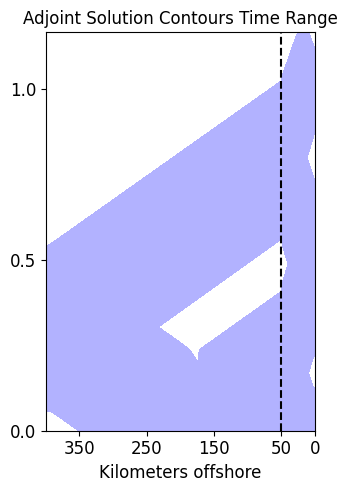